# Imports & Setup


In [1]:
import json
import random
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix

artifact_root = Path(r'D:\EEG Experiment Artifacts\2026-11-02')
dataset_root = Path(r'C:\FACED dataset')

import pickle
import zipfile
import scipy.io as sio
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torch_geometric.nn import GATConv, global_mean_pool

torch.set_num_threads(4)
ROOT = artifact_root

def write_json(path, value):
    path.write_text(json.dumps(value, indent=2), encoding='utf-8')


# Config


In [2]:
run_dir = artifact_root / 'runs/embedding32_gat_lstm_subject_holdout_v2'
config = json.loads((run_dir / 'config.json').read_text())
run_training = False

seed = 42
epochs = 10
batch_size = 8
embedding_dim = 32
num_classes = 8
learning_rate = 0.001
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print('Device:', device)
print('Labels: argmax of the first eight self-rating scores')
print('Subjects: train 000-079, validation 080-099, test 100-122')
print('Saved run: 2026-11-02. Training is disabled while loading its results.')


Device: cuda
Labels: argmax of the first eight self-rating scores
Subjects: train 000-079, validation 080-099, test 100-122
Saved run: 2026-11-02. Training is disabled while loading its results.


# Load & Preprocess & Split Data


In [3]:
def prepare(dataset_root):
    cache = ROOT / 'cache'
    cache.mkdir(exist_ok=True)
    signal_path = cache / 'raw_windows_30ch.npy'
    label_path = cache / 'labels8.npz'
    complete = cache / 'complete.json'
    if complete.exists():
        return (signal_path, label_path)
    signals = np.lib.format.open_memmap(signal_path, mode='w+', dtype='float32', shape=(123 * 28, 30, 30, 250))
    labels, subjects, videos = ([], [], [])
    archive = dataset_root / 'Other Files' / 'Processed_data.zip'
    sources = []
    with zipfile.ZipFile(archive) as z:
        members = {Path(p).name.split('.')[0]: p for p in z.namelist() if p.endswith('.pkl')}
        assert len(members) == 123, len(members)
        for sub in range(123):
            name = f'sub{sub:03d}'
            member = members[name]
            with z.open(member) as f:
                eeg = np.asarray(pickle.load(f))
            assert eeg.shape == (28, 32, 7500), eeg.shape
            eeg = eeg[:, :30].astype(np.float32)
            assert np.isfinite(eeg).all(), name
            eeg -= eeg.mean(axis=-1, keepdims=True)
            eeg /= np.maximum(eeg.std(axis=-1, keepdims=True), 1e-06)
            signals[sub * 28:(sub + 1) * 28] = eeg.reshape(28, 30, 30, 250).transpose(0, 2, 1, 3)
            remark_path = dataset_root / 'Data' / name / 'After_remarks.mat'
            remark = sio.loadmat(remark_path)['After_remark']
            ids = np.array([int(v.item()) for v in remark['vid'].ravel()])
            scores = np.stack([s.ravel() for s in remark['score'].ravel()])
            assert np.array_equal(np.sort(ids), np.arange(1, 29)), name
            target = scores[np.argsort(ids), :8].argmax(axis=1)
            labels.extend(target.tolist())
            subjects.extend([sub] * 28)
            videos.extend(range(1, 29))
            info = z.getinfo(member)
            sources.append({'subject': name, 'member': member, 'crc32': f'{info.CRC:08x}', 'size': info.file_size, 'label_sha256': hashlib.sha256(remark_path.read_bytes()).hexdigest()})
            if (sub + 1) % 10 == 0 or sub == 122:
                print(f'Prepared {sub + 1}/123 subjects', flush=True)
    signals.flush()
    del signals
    np.savez(label_path, labels=labels, subjects=subjects, videos=videos)
    write_json(complete, {'sources': sources, 'shape': [3444, 30, 30, 250], 'normalization': 'per trial/channel temporal z-score, epsilon floor 1e-6'})
    return (signal_path, label_path)

class Trials(Dataset):

    def __init__(self, path, labels, indices):
        self.x = np.load(path, mmap_mode='r')
        self.labels, self.indices = (labels, indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        return (torch.from_numpy(self.x[j].copy()), int(self.labels[j]))

signal_path = artifact_root / 'cache/raw_windows_30ch.npy'
label_path = artifact_root / 'cache/labels8.npz'
if not signal_path.exists() or not label_path.exists():
    signal_path, label_path = prepare(dataset_root)

meta = np.load(label_path)
labels, subjects = meta['labels'], meta['subjects']
split = np.load(run_dir / 'split_indices.npz')
indices = {name: split[name] for name in ['train', 'val', 'test']}
assert np.array_equal(labels, split['labels'])
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    assert not set(subjects[indices[a]]) & set(subjects[indices[b]])

generator = torch.Generator().manual_seed(seed)
loaders = {
    name: DataLoader(Trials(signal_path, labels, idx), batch_size=batch_size,
                     shuffle=name == 'train', num_workers=0,
                     generator=generator if name == 'train' else None)
    for name, idx in indices.items()
}
print('Input: 30 one-second windows, 30 EEG channels, 250 samples per window')
print({name: len(idx) for name, idx in indices.items()})


Input: 30 one-second windows, 30 EEG channels, 250 samples per window
{'train': 2240, 'val': 560, 'test': 644}


# Embedding + GAT + LSTM Model


In [4]:
class ChannelEncoder(nn.Module):

    def __init__(self, embedding_dim=32):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(1, 8, 15, stride=5, padding=7), nn.GELU(), nn.Conv1d(8, 16, 7, stride=2, padding=3), nn.GELU(), nn.AdaptiveAvgPool1d(8), nn.Flatten(), nn.Linear(16 * 8, embedding_dim), nn.LayerNorm(embedding_dim))

    def forward(self, x):
        return self.net(x)

class EmbeddingGATLSTM(nn.Module):

    def __init__(self, edge_index, embedding_dim=32, num_classes=8):
        super().__init__()
        self.encoder = ChannelEncoder(embedding_dim)
        self.gat1 = GATConv(embedding_dim, 16, heads=4, dropout=0.2)
        self.gat2 = GATConv(64, 16, heads=1, dropout=0.2)
        self.lstm = nn.LSTM(16, 64, batch_first=True)
        self.fc = nn.Linear(64, num_classes)
        self.register_buffer('base_edges', edge_index)
        self._graph_cache = {}

    def forward(self, x):
        b, t, n, samples = x.shape
        h = self.encoder(x.reshape(b * t * n, 1, samples))
        count = b * t
        key = (count, x.device)
        if key not in self._graph_cache:
            offsets = torch.arange(count, device=x.device) * n
            edges = (self.base_edges[:, None, :] + offsets[None, :, None]).reshape(2, -1)
            membership = torch.arange(count, device=x.device).repeat_interleave(n)
            self._graph_cache[key] = (edges, membership)
        edges, membership = self._graph_cache[key]
        h = F.elu(self.gat1(h, edges))
        h = F.elu(self.gat2(h, edges))
        h = global_mean_pool(h, membership, size=count).reshape(b, t, 16)
        h, _ = self.lstm(h)
        return self.fc(h[:, -1])

# The saved graph follows the official preprocessed channel order.
checkpoint = torch.load(run_dir / 'best_model.pt', map_location='cpu', weights_only=False)
edge_index = checkpoint['model_state_dict']['base_edges']
model = EmbeddingGATLSTM(edge_index, embedding_dim, num_classes).to(device)
if not run_training:
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
print(model)
print('Parameters:', sum(p.numel() for p in model.parameters()))


EmbeddingGATLSTM(
  (encoder): ChannelEncoder(
    (net): Sequential(
      (0): Conv1d(1, 8, kernel_size=(15,), stride=(5,), padding=(7,))
      (1): GELU(approximate='none')
      (2): Conv1d(8, 16, kernel_size=(7,), stride=(2,), padding=(3,))
      (3): GELU(approximate='none')
      (4): AdaptiveAvgPool1d(output_size=8)
      (5): Flatten(start_dim=1, end_dim=-1)
      (6): Linear(in_features=128, out_features=32, bias=True)
      (7): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    )
  )
  (gat1): GATConv(32, 16, heads=4)
  (gat2): GATConv(64, 16, heads=1)
  (lstm): LSTM(16, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=8, bias=True)
)
Parameters: 30056


# Training and Evaluation


In [5]:
def pass_epoch(model, loader, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, truth, predictions = (0.0, [], [])
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = (x.to(device), y.to(device))
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite loss')
            if training:
                loss.backward()
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                if not torch.isfinite(norm):
                    raise FloatingPointError('Nonfinite gradient')
                optimizer.step()
            loss_sum += loss.item() * len(y)
            truth.extend(y.detach().cpu().tolist())
            predictions.extend(logits.argmax(1).detach().cpu().tolist())
    return ({'loss': loss_sum / len(truth), 'accuracy': accuracy_score(truth, predictions), 'balanced_accuracy': balanced_accuracy_score(truth, predictions), 'macro_f1': f1_score(truth, predictions, average='macro', zero_division=0)}, np.array(truth), np.array(predictions))


# Run Training


In [6]:
if run_training:
    run_dir = artifact_root / 'runs' / ('embedding32_gat_lstm_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
    run_dir.mkdir(parents=True, exist_ok=False)
    config = dict(config, run_name=run_dir.name, seed=seed, epochs=epochs,
                  batch_size=batch_size, embedding_dim=embedding_dim)
    write_json(run_dir / 'config.json', config)
    np.savez(run_dir / 'split_indices.npz', **indices, labels=labels,
             subjects=subjects, videos=meta['videos'])
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history_rows, best_score = [], -1
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        train, _, _ = pass_epoch(model, loaders['train'], device, optimizer)
        val, _, _ = pass_epoch(model, loaders['val'], device)
        row = {'epoch': epoch, 'seconds': time.perf_counter() - t0,
               **{'train_' + k: v for k, v in train.items()},
               **{'val_' + k: v for k, v in val.items()}}
        history_rows.append(row)
        pd.DataFrame(history_rows).to_csv(run_dir / 'history.csv', index=False)
        if val['balanced_accuracy'] > best_score:
            best_score = val['balanced_accuracy']
            torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch,
                        'config': config, 'validation': val}, run_dir / 'best_model.pt')
        print(f"Epoch {epoch}/{epochs} - Train: {train['accuracy']:.4f} - Val: {val['accuracy']:.4f}")

    checkpoint = torch.load(run_dir / 'best_model.pt', map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    metrics, truth, predictions = pass_epoch(model, loaders['test'], device)
    np.savez(run_dir / 'test_predictions.npz', truth=truth, predictions=predictions,
             subjects=subjects[indices['test']], videos=meta['videos'][indices['test']])
    majority = np.bincount(labels[indices['train']], minlength=8).argmax()
    write_json(run_dir / 'metrics.json', {
        'test': metrics, 'best_epoch': checkpoint['epoch'],
        'validation': checkpoint['validation'],
        'training_seconds': time.perf_counter() - start,
        'majority_baseline_accuracy': float(np.mean(truth == majority))})
else:
    print('Loaded saved training history; no training was repeated.')

history = pd.read_csv(run_dir / 'history.csv')
print(history[['epoch', 'train_loss', 'val_loss', 'train_accuracy', 'val_accuracy']].to_string(index=False))


Loaded saved training history; no training was repeated.
 epoch  train_loss  val_loss  train_accuracy  val_accuracy
     1    2.051914  2.064840        0.162946      0.157143
     2    2.045368  2.073792        0.169196      0.126786
     3    2.042199  2.066117        0.171875      0.128571
     4    2.034782  2.069483        0.182589      0.135714
     5    2.026028  2.058398        0.168304      0.180357
     6    2.007649  2.058212        0.204464      0.196429
     7    1.973349  2.035469        0.210714      0.219643
     8    1.932062  2.094171        0.244643      0.189286
     9    1.896056  2.070893        0.260714      0.203571
    10    1.869986  2.058064        0.279018      0.212500


# Test Results


In [7]:
results = json.loads((run_dir / 'metrics.json').read_text())
saved_predictions = np.load(run_dir / 'test_predictions.npz')
truth, predictions = saved_predictions['truth'], saved_predictions['predictions']
test_metrics = {
    'Accuracy': accuracy_score(truth, predictions),
    'Balanced accuracy': balanced_accuracy_score(truth, predictions),
    'Macro F1': f1_score(truth, predictions, average='macro'),
    'Majority baseline accuracy': results['majority_baseline_accuracy']
}
assert np.isclose(test_metrics['Accuracy'], results['test']['accuracy'])
print(pd.Series(test_metrics).mul(100).round(2).to_string())
print('Best epoch:', results['best_epoch'])
print('Correct:', int(np.sum(truth == predictions)), '/', len(truth))
print('Eight self-rating classes; this is a separate task from FACED stimulus labels.')
print('The initial run has lower accuracy than the majority baseline.')


Accuracy                      18.79
Balanced accuracy             15.83
Macro F1                      14.26
Majority baseline accuracy    21.12
Best epoch: 10
Correct: 121 / 644
Eight self-rating classes; this is a separate task from FACED stimulus labels.
The initial run has lower accuracy than the majority baseline.


# Plot Results


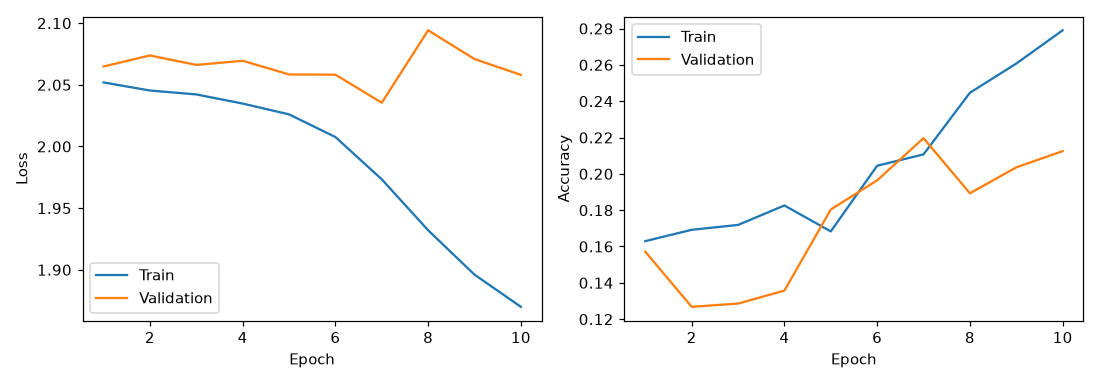

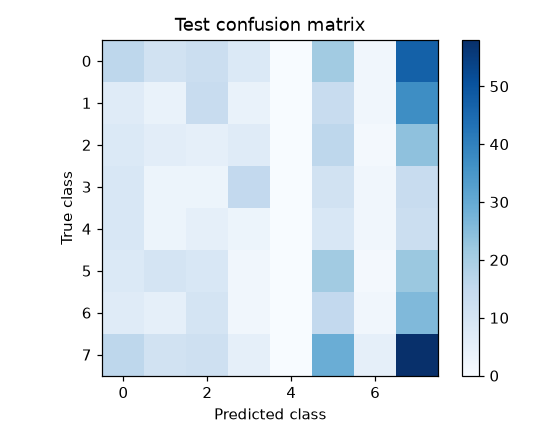

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history['epoch'], history['train_loss'], label='Train')
axes[0].plot(history['epoch'], history['val_loss'], label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Loss')
axes[1].plot(history['epoch'], history['train_accuracy'], label='Train')
axes[1].plot(history['epoch'], history['val_accuracy'], label='Validation')
axes[1].set(xlabel='Epoch', ylabel='Accuracy')
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(confusion_matrix(truth, predictions, labels=np.arange(8)), cmap='Blues')
ax.set(xlabel='Predicted class', ylabel='True class', title='Test confusion matrix')
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()
